In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict, Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN, MiniBatchKMeans, SpectralClustering, BisectingKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score


import warnings
warnings.filterwarnings("ignore", message="n_jobs value 1 overridden")

They are a few problems in the dataset given :

    - No header : no first line to determine the name of the columns.
        -> we can fix it by specifing the column's name when we read the csv.
    - Missing values : color is missing in some rows.
        -> replace missing values by default 0x000000 (white).

In [129]:
df = pd.read_csv("Student_Dataset.csv", delimiter=",", on_bad_lines="warn", names=["id", "color", "testimony"], engine='python', header=None)

def fix_row(row) -> pd.Series:
    values        = row.dropna().tolist()
    id_val        = values[0]
    testimony_val = values[-1]
    color_val     = values[1] if len(values) > 2 else "0x000000"
    return pd.Series([id_val, color_val, testimony_val], index=["id", "color", "testimony"])

df_fixed = df.apply(fix_row, axis=1)

df_fixed.info()
df_fixed.head()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1011 entries, 0 to 1010
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         1011 non-null   int64 
 1   color      1011 non-null   object
 2   testimony  1011 non-null   object
dtypes: int64(1), object(2)
memory usage: 23.8+ KB


,id,color,testimony
0,1,0x000000,On uneven paths the heel feels wobbly side‑to‑...
1,2,0x000000,"The feverish feeling eased, but I’m now breath..."
2,3,0x000000,"While working in the garden, I touched a metal..."
3,4,0x000000,A short sprint brought on a twinge in the midd...
4,5,0x000000,I accidentally left my hand on a hot mug for a...


The trick here is that the "read_csv" automaticly put the tesminonies in the "color" column. So we need to force the testimonies to go in the last column and repace the value in "color" by default 0x000000 (black).

We convert the values in the "testimony" column in str for easier manipulation later.

In [130]:
df_clean = df.dropna(subset=["testimony"]).copy()

corpus = df_clean["testimony"].astype(str).tolist()

We use a small function to change the color code (0x000000) to something usable for matplotlib (#000000).

In [131]:
def fix_color(c):
    if isinstance(c, str) and c.startswith("0x"):
        return "#" + c[2:]
    return "#000000"

colors = df_clean["color"].fillna("0x000000").apply(fix_color)

https://colab.research.google.com/drive/10jcxkl76JtUDWjHJJGjtITV4c-ducvAl#scrollTo=zaOU4LkIcbuc


https://youtu.be/NTsvXfT_wzA?si=jmFfT8ESEYRACQl2

(doc for clustering algo)



First we need to "embed" the text. It means to convert the sentences and the words into numerical objects.
It will also allow us to do more cleaning to :
    - elimate very frequent words
    - elimate very rare words
    - remove all "filling" words in english like pronouns


In [132]:
custom_stopwords = {'ache', 'aches', 'feel', 'feels', 'area', 'pain', '37'} # we remove some words that are not sepcific or discrimitave enough in this context

all_stopwords = list(ENGLISH_STOP_WORDS.union(custom_stopwords))

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words=all_stopwords,
    max_df=0.6, # elimate the words that appear in more than 60% of the dataset
    min_df=0.01, # elimate the words that appear in less than 1% of the dataset
    ngram_range=(1, 2),
    sublinear_tf=True,
    max_features=5000
)

X = vectorizer.fit_transform(corpus)

print(vectorizer.get_feature_names_out())
print(X.shape)

['abdomen' 'ago' 'air' 'ankle' 'appear' 'appeared' 'appears' 'arm' 'arms'
 'avoid' 'bad' 'band' 'bathroom' 'bed' 'began' 'bending' 'better' 'big'
 'bit' 'blister' 'blisters' 'blocked' 'blood' 'blood pressure' 'blurs'
 'body' 'breath' 'breathe' 'breathing' 'bright' 'brings' 'bumps' 'burning'
 'calf' 'car' 'catch' 'catch breath' 'changed' 'chest' 'chest tight'
 'child' 'cleaning' 'clear' 'cold' 'congested' 'congestion' 'constant'
 'cough' 'coughing' 'couple' 'cup' 'day' 'days' 'deep' 'deep breath'
 'developed' 'didn' 'dizzy' 'doctor' 'doesn' 'don' 'drinking' 'dry'
 'dry cough' 'dull' 'ear' 'ears' 'eases' 'eat' 'edge' 'elbow' 'especially'
 'evening' 'experienced' 'eye' 'eyes' 'face' 'faint' 'family' 'fast'
 'fatigue' 'feeling' 'felt' 'fever' 'feverish' 'fine' 'fingers' 'flares'
 'flat' 'flickers' 'flight' 'flu' 'foot' 'forearm' 'forward' 'frequent'
 'frequently' 'gets' 'gets worse' 'getting' 'gives' 'going' 'got' 'groin'
 'gums' 'hair' 'hand' 'hands' 'happening' 'hard' 'haven' 'having' 'h

2. SVD + NORMALIZATION

In [133]:
svd = TruncatedSVD(n_components=300, random_state=42)
X_reduced = svd.fit_transform(X)

X_reduced = Normalizer().fit_transform(X_reduced)

We can't use directly Kmeans since we don't know the exact number of cluster we will have (instead of cluster you can imagine "categories" like *tooth aches*, *mental trouble*, *broken bone*...)
So we use a "silhouette score" for each k to determine which seems better

In [134]:
best_score = -1
best_k = None

for k in range(2, 10):
    model = KMeans(n_clusters=k, random_state=42)
    labels_tmp = model.fit_predict(X_reduced)

    score = silhouette_score(X_reduced, labels_tmp)

    if score > best_score:
        best_score = score
        best_k = k

    print(f"Best k: {best_k} with score {best_score}\n")

print(f"Final Best k: {best_k} with score {best_score}\n")

# the final model with the best k
model = KMeans(n_clusters=best_k, random_state=42)
labels = model.fit_predict(X_reduced)


Best k: 2 with score 0.01411185441423412

Best k: 3 with score 0.018060878555329226

Best k: 4 with score 0.023338327673049133

Best k: 5 with score 0.025432531516276616

Best k: 5 with score 0.025432531516276616

Best k: 5 with score 0.025432531516276616

Best k: 8 with score 0.030031567475190826

Best k: 9 with score 0.030988214278319635

Final Best k: 9 with score 0.030988214278319635



A good silhouette score would be something around 0.5. You can imagine that a score of 0.03 is terrible (it is worst than random)
For the project we decided to push the analise a bit further to understand what is going on.

To have a better vision of the clusters created, we print the most frequent words in each cluster

In [135]:
terms = vectorizer.get_feature_names_out()
centroids = model.cluster_centers_

for i, center in enumerate(centroids):
    top_indices = center.argsort()[-10:][::-1]
    print([terms[j] for j in top_indices])

analyzer = vectorizer.build_analyzer()

for i in range(best_k):
    texts = [corpus[j] for j in range(len(labels)) if labels[j] == i]
    
    tokens = []
    for t in texts:
        tokens.extend(analyzer(t))
    
    common = Counter(tokens).most_common(10)
    print([w for w, _ in common])

['arm', 'abdomen', 'avoid', 'ankle', 'blister', 'air', 'arms', 'better', 'congestion', 'body']
['abdomen', 'appear', 'appears', 'air', 'began', 'bad', 'bending', 'avoid', 'bright', 'calf']
['abdomen', 'ankle', 'bed', 'air', 'ago', 'body', 'burning', 'began', 'bathroom', 'days']
['ago', 'abdomen', 'breathe', 'appears', 'blood pressure', 'bending', 'arms', 'blood', 'calf', 'elbow']
['abdomen', 'ankle', 'appeared', 'appear', 'ago', 'avoid', 'congested', 'cough', 'blurs', 'fever']
['abdomen', 'appears', 'arms', 'appeared', 'avoid', 'began', 'bit', 'flickers', 'blurs', 'evening']
['abdomen', 'bathroom', 'ankle', 'appear', 'arms', 'arm', 'band', 'big', 'air', 'appears']
['abdomen', 'blisters', 'appear', 'appeared', 'bad', 'cleaning', 'blood', 'arm', 'constant', 'fast']
['air', 'abdomen', 'ago', 'appeared', 'better', 'band', 'bathroom', 'catch', 'avoid', 'big']
['pressure', 'blood', 'blood pressure', 'doctor', 'told', 'high', 'didn', 'sugar', 'especially', 'chest']
['breath', 'deep', 'short',

We can see that the words are very similar in all the cluster. Which is not the expected result.

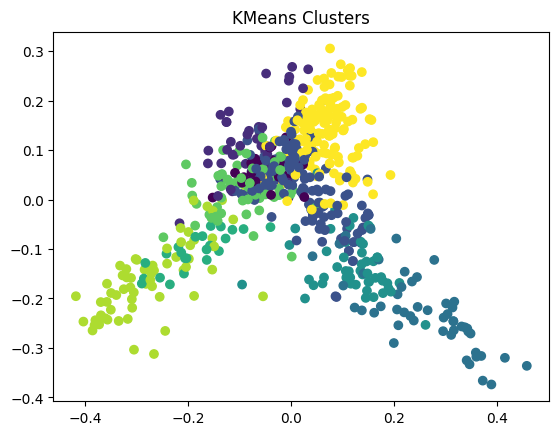

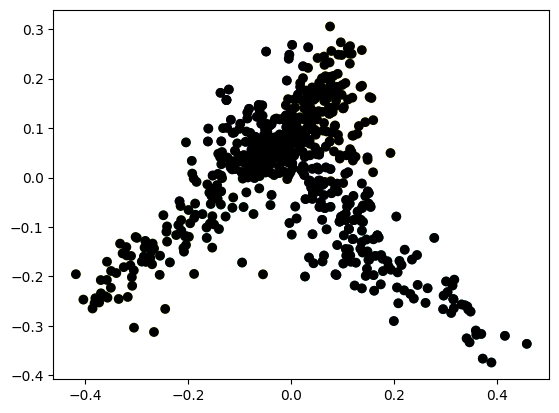

In [136]:
df_clean["cluster"] = labels

true_labels = LabelEncoder().fit_transform(df_clean["color"].fillna("unknown"))

ari = adjusted_rand_score(true_labels, df_clean["cluster"])

X_2d = PCA(n_components=2).fit_transform(X_reduced)


plt.figure() 
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels) 
plt.title("KMeans Clusters") 
plt.show()

plt.figure() 
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=colors)
plt.show()

Test with another embeder

Step 1 — Import embedding model

from sentence_transformers import SentenceTransformer


Step 2 — Load pretrained model

model = SentenceTransformer('all-MiniLM-L6-v2')

Step 3 — Encode your corpus

X = model.encode(corpus)

👉 Output:

shape ≈ (n_samples, 384)

dense vectors (not sparse like TF-IDF)

Step 4 — Normalize vectors

from sklearn.preprocessing import Normalizer

X = Normalizer().fit_transform(X)

👉 Important for cosine similarity

🔹 Step 5 — (Optional) Dimensionality reduction

from sklearn.decomposition import PCA

X_reduced = PCA(n_components=50).fit_transform(X)

👉 Often optional (embeddings are already compact)

🔹 Step 6 — Clustering

Choose one:

Option A:

from sklearn.cluster import KMeans

KMeans.fit_predict()

Option B:

from sklearn.cluster import AgglomerativeClustering

AgglomerativeClustering.fit_predict()

🔹 Step 7 — Hyperparameter search

Loop over k

Use:

silhouette_score

🔹 Step 8 — Evaluation

from sklearn.metrics import adjusted_rand_score

Compare with color column

🔹 Step 9 — Visualization

from sklearn.decomposition import PCA

matplotlib.pyplot.scatter

🔹 Step 10 — Interpretation

Since embeddings don’t have words:

👉 You must:

print sample texts per cluster

manually interpret themes

Test with UMAP

In [137]:
import umap

results = []

umap_model = umap.UMAP(
    n_components=20,
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)

X_reduced = umap_model.fit_transform(X)

Comparative function

In [138]:
def umap_clustering_search(X, model_builder, model_name):
    import umap
    from sklearn.metrics import silhouette_score

    best_score = -1
    best_params = None
    results = []

    for n_comp in [10, 20, 50]:
        for n_neigh in [10, 15, 30]:
            for min_dist in [0.0, 0.1, 0.3]:

                umap_model = umap.UMAP(
                    n_components=n_comp,
                    n_neighbors=n_neigh,
                    min_dist=min_dist,
                    metric='cosine',
                    random_state=42
                )

                X_reduced = umap_model.fit_transform(X)

                for k in range(2, 10):

                    model = model_builder(k)

                    labels = model.fit_predict(X_reduced)
                    score = silhouette_score(X_reduced, labels)

                    results.append({
                        "model": model_name,
                        "n_components": n_comp,
                        "n_neighbors": n_neigh,
                        "min_dist": min_dist,
                        "k": k,
                        "score": score
                    })

                    if score > best_score:
                        best_score = score
                        best_params = (n_comp, n_neigh, min_dist, k)

    print(f"Best parameters for {model_name} => score: {best_score} with {best_params}")

    return best_params, best_score, results

Kmeans

In [139]:
best_params, best_score, results = umap_clustering_search(
    X,
    lambda k: KMeans(n_clusters=k, random_state=42),
    "KMeans"
)

Best parameters for KMeans => score: 0.5044174194335938 with (10, 10, 0.0, 9)


Agglomerative search

In [140]:
best_params, best_score, results = umap_clustering_search(
    X,
    lambda k: AgglomerativeClustering(n_clusters=k),
    "Agglomerative"
)

Best parameters for Agglomerative => score: 0.500411868095398 with (10, 10, 0.0, 9)


MiniBatchKMeans

In [141]:
best_params, best_score, results = umap_clustering_search(
    X,
    lambda k: MiniBatchKMeans(n_clusters=k, random_state=42),
    "MiniBatchKMeans"
)

Best parameters for MiniBatchKMeans => score: 0.4930863380432129 with (10, 10, 0.0, 7)


BisectingKMeans

In [142]:
best_params, best_score, results = umap_clustering_search(
    X,
    lambda k: BisectingKMeans(n_clusters=k, random_state=42),
    "BisectingKMeans"
)

Best parameters for BisectingKMeans => score: 0.4701441526412964 with (10, 15, 0.0, 7)


Spectral

In [143]:
best_params, best_score, results = umap_clustering_search(
    X,
    lambda k: SpectralClustering(n_clusters=k, assign_labels='kmeans'),
    "Spectral"
)

Best parameters for Spectral => score: 0.5090886950492859 with (10, 10, 0.0, 9)


Final result

model           Spectral
n_components          10
n_neighbors           10
min_dist             0.0
k                      9
score           0.509089
Name: 7, dtype: object


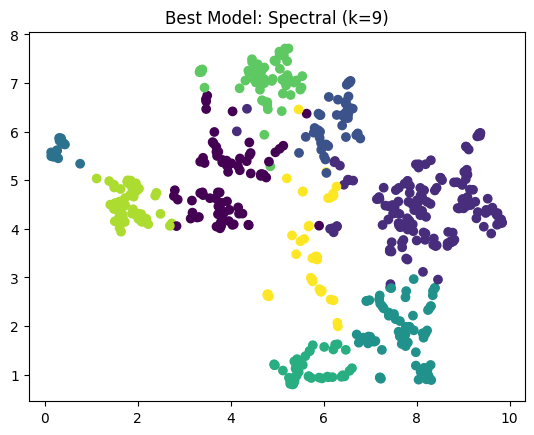

In [144]:
df_results = pd.DataFrame(results)

best_row = df_results.sort_values("score", ascending=False).iloc[0]
print(best_row)

best_model_name = best_row["model"]
best_k = int(best_row["k"])
n_comp = int(best_row["n_components"])
n_neigh = int(best_row["n_neighbors"])
min_dist = float(best_row["min_dist"])


# rebuild UMAP
umap_best = umap.UMAP(
    n_components=n_comp,
    n_neighbors=n_neigh,
    min_dist=min_dist,
    metric='cosine',
    random_state=42
)

X_best = umap_best.fit_transform(X)

# rebuild model
model_dict = {
    "KMeans": lambda k: KMeans(n_clusters=k, random_state=42),
    "Agglomerative": lambda k: AgglomerativeClustering(n_clusters=k),
    "MiniBatchKMeans": lambda k: MiniBatchKMeans(n_clusters=k, random_state=42),
    "BisectingKMeans": lambda k: BisectingKMeans(n_clusters=k, random_state=42),
    "Spectral": lambda k: SpectralClustering(n_clusters=k, assign_labels='kmeans')
}

model = model_dict[best_model_name](best_k)
labels_best = model.fit_predict(X_best)

umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=n_neigh,
    min_dist=min_dist,
    metric='cosine',
    random_state=42
)

X_2d = umap_2d.fit_transform(X)

plt.figure()
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels_best)
plt.title(f"Best Model: {best_model_name} (k={best_k})")
plt.show()

New test with hdscan

In [145]:
hdscan_results = []

def umap_hdbscan_search(X):
    best_score = -1
    best_params = None

    for n_comp in [10, 20, 50]:
        for n_neigh in [10, 15, 30]:
            for min_dist in [0.0, 0.1, 0.3]:

                umap_model = umap.UMAP(
                    n_components=n_comp,
                    n_neighbors=n_neigh,
                    min_dist=min_dist,
                    metric='cosine',
                    random_state=42
                )

                X_reduced = umap_model.fit_transform(X)

                for min_cluster_size in [5, 10, 20]:

                    model = HDBSCAN(
                        copy=True,
                        min_cluster_size=min_cluster_size
                    )

                    labels = model.fit_predict(X_reduced)

                    if len(set(labels)) <= 1:
                        continue

                    score = silhouette_score(X_reduced, labels)

                    hdscan_results.append({
                        "model": "HDBSCAN",
                        "n_components": n_comp,
                        "n_neighbors": n_neigh,
                        "min_dist": min_dist,
                        "min_cluster_size": min_cluster_size,
                        "score": score
                    })

                    if score > best_score:
                        best_score = score
                        best_params = (n_comp, n_neigh, min_dist, min_cluster_size)

    print(f"Best HDBSCAN => score: {best_score}, params: {best_params}")
    # return best_params, best_score

umap_hdbscan_search(X_reduced)

Best HDBSCAN => score: 0.7455299496650696, params: (10, 10, 0.0, 10)


      model  n_components  n_neighbors  min_dist  min_cluster_size     score
1   HDBSCAN            10           10       0.0                10  0.745530
55  HDBSCAN            50           10       0.0                10  0.732266
11  HDBSCAN            10           15       0.0                20  0.729854
38  HDBSCAN            20           15       0.0                20  0.721205
29  HDBSCAN            20           10       0.0                20  0.707764
2   HDBSCAN            10           10       0.0                20  0.706255
37  HDBSCAN            20           15       0.0                10  0.697039
56  HDBSCAN            50           10       0.0                20  0.696845
32  HDBSCAN            20           10       0.1                20  0.694817
41  HDBSCAN            20           15       0.1                20  0.691662


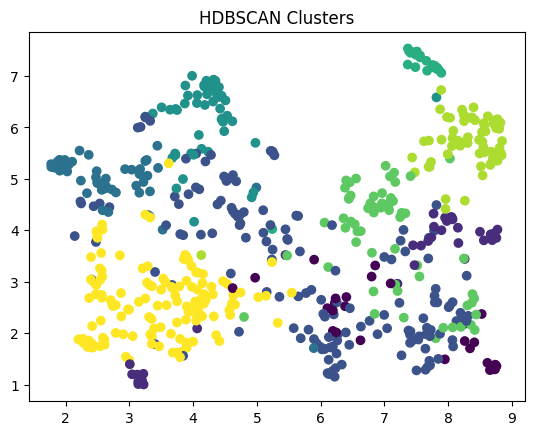

In [146]:
hdscan_df_results = pd.DataFrame(hdscan_results)
print(hdscan_df_results.sort_values("score", ascending=False).head(10))

umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric='cosine',
    random_state=42
)

X_2d = umap_2d.fit_transform(X)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.title("HDBSCAN Clusters")
plt.show()